In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values between 0 and 1

x_train = x_train.astype("float32") / 255.0

x_test = x_test.astype("float32") / 255.0

# Train only on normal images (digit 0)

x_train = x_train[y_train == 0]

# Prepare test images of digit 0 and digit 1

x_test = x_test[np.isin(y_test, [0, 1])]

y_test = y_test[np.isin(y_test, [0, 1])]

In [3]:
x_train = x_train.reshape(-1, 784)

x_test = x_test.reshape(-1, 784)

In [4]:
input_layer = keras.Input(shape=(784,))

# Encoder

encoded = layers.Dense(128, activation="relu")(input_layer)

encoded = layers.Dense(32, activation="relu")(encoded)

# Decoder

decoded = layers.Dense(128, activation="relu")(encoded)

output_layer = layers.Dense(784, activation="sigmoid")(decoded)

autoencoder = keras.Model(input_layer, output_layer)

In [5]:
autoencoder.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)

In [6]:
autoencoder.fit(

    x_train,

    x_train,

    epochs=5,

    batch_size=128,

    validation_split=0.1

)

Epoch 1/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.1047 - mae: 0.2292 - val_loss: 0.0580 - val_mae: 0.1265
Epoch 2/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0494 - mae: 0.1110 - val_loss: 0.0416 - val_mae: 0.0962
Epoch 3/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0391 - mae: 0.0935 - val_loss: 0.0352 - val_mae: 0.0870
Epoch 4/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0341 - mae: 0.0862 - val_loss: 0.0310 - val_mae: 0.0812
Epoch 5/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0296 - mae: 0.0790 - val_loss: 0.0262 - val_mae: 0.0721


In [7]:
reconstructed = autoencoder.predict(x_test)

error = np.mean((x_test - reconstructed) ** 2, axis=1)

threshold = np.percentile(error[y_test == 0], 95)

print("Anomaly threshold:", threshold)

67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Anomaly threshold: 0.04835765


In [8]:
predictions = error > threshold

for i in range(10):

    if predictions[i]:

        print("Image", i, "- Anomaly")

    else:

        print("Image", i, "- Normal")

Image 0 - Anomaly
Image 1 - Normal
Image 2 - Anomaly
Image 3 - Normal
Image 4 - Normal
Image 5 - Anomaly
Image 6 - Normal
Image 7 - Normal
Image 8 - Anomaly
Image 9 - Anomaly


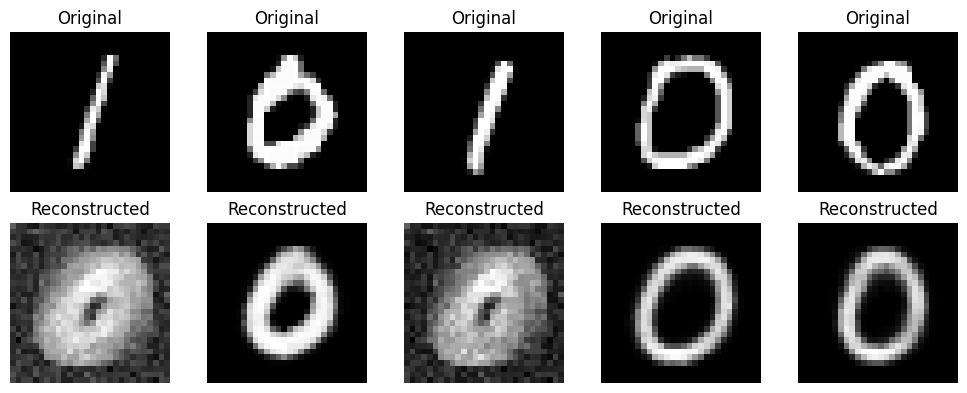

In [9]:
plt.figure(figsize=(10, 4))

for i in range(5):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")

    plt.title("Original")

    plt.axis("off")

    plt.subplot(2, 5, i + 6)

    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")

    plt.title("Reconstructed")

    plt.axis("off")

plt.tight_layout()

plt.show()